# **Libs**

In [ ]:
!pip install git+https://github.com/tensorflow/examples.git

  Cloning https://github.com/tensorflow/examples.git to /tmp/pip-req-build-5t41rgsj
  Running command git clone --filter=blob:none --quiet https://github.com/tensorflow/examples.git /tmp/pip-req-build-5t41rgsj
  Resolved https://github.com/tensorflow/examples.git to commit 73b59711cf61eeb38ebcf73afa7a94760f5d39f2
  Preparing metadata (setup.py) ... done
  Created wheel for tensorflow-examples: filename=tensorflow_examples-0.1737028257.660583533541310210890884570123443050065537350130-py3-none-any.whl size=301603 sha256=391e9b07b8160e719470b4ca0e34bc90f4e7e6201b3603da8003986b5c916e9c
  Stored in directory: /tmp/pip-ephem-wheel-cache-bwbi1_be/wheels/91/9b/e8/6ae2ecc930bd726c578e35b313e987a687bc5ce03c3a42c2d5
Successfully built tensorflow-examples


In [ ]:
import tensorflow_datasets as tfds
from tensorflow_examples.models.pix2pix import pix2pix

import os
import time
import matplotlib.pyplot as plt
from IPython.display import clear_output
import tensorflow as tf

AUTOTUNE = tf.data.AUTOTUNE

# **Data Loading**

In [ ]:
data,metadata = tfds.load(name='cycle_gan/horse2zebra',as_supervised=True,with_info=True)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/4 [00:00<?, ? splits/s]

Generating trainA examples...:   0%|          | 0/1067 [00:00<?, ? examples/s]

Shuffling /root/tensorflow_datasets/cycle_gan/horse2zebra/incomplete.IQ5Z9W_3.0.0/cycle_gan-trainA.tfrecord*..…

... (3 outputs left out)

Shuffling /root/tensorflow_datasets/cycle_gan/horse2zebra/incomplete.IQ5Z9W_3.0.0/cycle_gan-testA.tfrecord*...…

Generating testB examples...:   0%|          | 0/140 [00:00<?, ? examples/s]

Shuffling /root/tensorflow_datasets/cycle_gan/horse2zebra/incomplete.IQ5Z9W_3.0.0/cycle_gan-testB.tfrecord*...…

Dataset cycle_gan downloaded and prepared to /root/tensorflow_datasets/cycle_gan/horse2zebra/3.0.0. Subsequent calls will reuse this data.


# **Split**

In [ ]:
Train_horse,Train_zebra = data['trainA'],data['trainB']
Test_horse,Test_zebra = data['testA'],data['testB']

In [ ]:
BUFFER_SIZE = 1000
BATCH_SIZE = 1
IMG_WIDTH = 256
IMG_HEIGHT = 256
EPOCHS = 50

# **Augmentation Techniques for Cycle Gan**

# **1.Random Jittering**
# **2.Random Mirroring**
# **3.Normalization**


In [ ]:
def random_jittering(image):

    # 1.resize

    image = tf.image.resize(images=image,size = [286,286], method=tf.image.ResizeMethod.NEAREST_NEIGHBOR)

    # 2.Cropping

    image = tf.image.random_crop(image,size=[IMG_WIDTH,IMG_HEIGHT,3])

    return image

In [ ]:
def Random_Mirroring(image):

    # 1.random flip

    image = tf.image.random_flip_left_right(image)

    return image


In [ ]:
def Normalize(image):

    image = tf.cast(image,dtype=tf.float32)
    image = (image - 127.5) /127.5

    return image

In [ ]:
def preprocess_traindata(image,labels):

    image = Normalize(image)
    image = random_jittering(image)
    image = Random_Mirroring(image)

    return image

In [ ]:
def preprocess_image_test(image, labels):

  image = Normalize(image)
  return image

# **Data Conversion**

In [ ]:
train_horses = Train_horse.cache().map(
    preprocess_traindata, num_parallel_calls=AUTOTUNE).shuffle(
    BUFFER_SIZE).batch(BATCH_SIZE)


train_zebras = Train_zebra.cache().map(
    preprocess_traindata, num_parallel_calls=AUTOTUNE).shuffle(
    BUFFER_SIZE).batch(BATCH_SIZE)

test_horses = Test_horse.cache().map(
    preprocess_image_test, num_parallel_calls=AUTOTUNE).shuffle(
    BUFFER_SIZE).batch(BATCH_SIZE)

test_zebras = Test_zebra.cache().map(
    preprocess_image_test, num_parallel_calls=AUTOTUNE).shuffle(
    BUFFER_SIZE).batch(BATCH_SIZE)

# **Generator an Discriminator**

In [ ]:
channels = 3

Generator_G = pix2pix.unet_generator(channels,norm_type='instancenorm')
Generator_F = pix2pix.unet_generator(channels,norm_type='instancenorm')


Discriminator_X = pix2pix.discriminator(norm_type='instancenorm', target=False)
Discriminator_Y = pix2pix.discriminator(norm_type='instancenorm', target=False)

# **Losses**

In [ ]:
LAMBDA = 10

In [ ]:
loss_obj = tf.keras.losses.BinaryCrossentropy(from_logits=True)

In [ ]:
def discriminator_loss(real, generated):
  real_loss = loss_obj(tf.ones_like(real), real)

  generated_loss = loss_obj(tf.zeros_like(generated), generated)

  total_disc_loss = real_loss + generated_loss

  return total_disc_loss * 0.5

In [ ]:
def generator_loss(generated):
  return loss_obj(tf.ones_like(generated), generated)

In [ ]:
def calc_cycle_loss(real_image, cycled_image):
  loss1 = tf.reduce_mean(tf.abs(real_image - cycled_image))

  return LAMBDA * loss1

In [ ]:
def identity_loss(real_image, same_image):
  loss = tf.reduce_mean(tf.abs(real_image - same_image))
  return LAMBDA * 0.5 * loss

# **Discriminator**

In [ ]:
Generator_G_Optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
Generator_F_Optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)

Discriminator_X_Optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
Discriminator_Y_Optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)

#  **Check Point**

In [ ]:
checkpoint_path = "./checkpoints/train"

ckpt = tf.train.Checkpoint(Generator_G=Generator_G,
                          Generator_F=Generator_F,
                           Discriminator_X=Discriminator_X,
                           Discriminator_Y=Discriminator_Y,
                           Generator_G_Optimizer=Generator_G_Optimizer,
                           Generator_F_Optimizer=Generator_F_Optimizer,
                           Discriminator_X_Optimizer=Discriminator_X_Optimizer,
                           Discriminator_Y_Optimizer =Discriminator_Y_Optimizer )

ckpt_manager = tf.train.CheckpointManager(ckpt, checkpoint_path, max_to_keep=5)

# if a checkpoint exists, restore the latest checkpoint.
if ckpt_manager.latest_checkpoint:
  ckpt.restore(ckpt_manager.latest_checkpoint)
  print ('Latest checkpoint restored!!')

In [ ]:
def generate_images(model, test_input):
  prediction = model(test_input)

  plt.figure(figsize=(12, 12))

  display_list = [test_input[0], prediction[0]]
  title = ['Input Image', 'Predicted Image']

  for i in range(2):
    plt.subplot(1, 2, i+1)
    plt.title(title[i])
    # getting the pixel values between [0, 1] to plot it.
    plt.imshow(display_list[i] * 0.5 + 0.5)
    plt.axis('off')
  plt.show()

In [ ]:
@tf.function
def train_step(real_x, real_y):
  # persistent is set to True because the tape is used more than
  # once to calculate the gradients.
  with tf.GradientTape(persistent=True) as tape:
    # Generator G translates X -> Y
    # Generator F translates Y -> X.

    fake_y = Generator_G(real_x, training=True)
    cycled_x = Generator_F(fake_y, training=True)

    fake_x = Generator_F(real_y, training=True)
    cycled_y = Generator_G(fake_x, training=True)

    # same_x and same_y are used for identity loss.
    same_x =Generator_F(real_x, training=True)
    same_y = Generator_G(real_y, training=True)

    disc_real_x = Discriminator_X(real_x, training=True)
    disc_real_y = Discriminator_Y(real_y, training=True)

    disc_fake_x = Discriminator_X(fake_x, training=True)
    disc_fake_y = Discriminator_Y(fake_y, training=True)

    # calculate the loss
    gen_g_loss = generator_loss(disc_fake_y)
    gen_f_loss = generator_loss(disc_fake_x)

    total_cycle_loss = calc_cycle_loss(real_x, cycled_x) + calc_cycle_loss(real_y, cycled_y)

    # Total generator loss = adversarial loss + cycle loss
    total_gen_g_loss = gen_g_loss + total_cycle_loss + identity_loss(real_y, same_y)
    total_gen_f_loss = gen_f_loss + total_cycle_loss + identity_loss(real_x, same_x)

    disc_x_loss = discriminator_loss(disc_real_x, disc_fake_x)
    disc_y_loss = discriminator_loss(disc_real_y, disc_fake_y)

  # Calculate the gradients for generator and discriminator
  generator_g_gradients = tape.gradient(total_gen_g_loss,
                                        Generator_G.trainable_variables)
  generator_f_gradients = tape.gradient(total_gen_f_loss,
                                        Generator_F.trainable_variables)

  discriminator_x_gradients = tape.gradient(disc_x_loss,
                                            Discriminator_X.trainable_variables)
  discriminator_y_gradients = tape.gradient(disc_y_loss,
                                            Discriminator_Y.trainable_variables)

  # Apply the gradients to the optimizer
  Generator_G_Optimizer.apply_gradients(zip(generator_g_gradients,
                                            Generator_G.trainable_variables))

  Generator_F_Optimizer.apply_gradients(zip(generator_f_gradients,
                                            Generator_F.trainable_variables))

  Discriminator_X_Optimizer.apply_gradients(zip(discriminator_x_gradients,
                                                Discriminator_X.trainable_variables))

  Discriminator_Y_Optimizer.apply_gradients(zip(discriminator_y_gradients,
                                                Discriminator_Y.trainable_variables))

In [ ]:
sample_horse = next(iter(train_horses))
sample_zebra = next(iter(train_zebras))



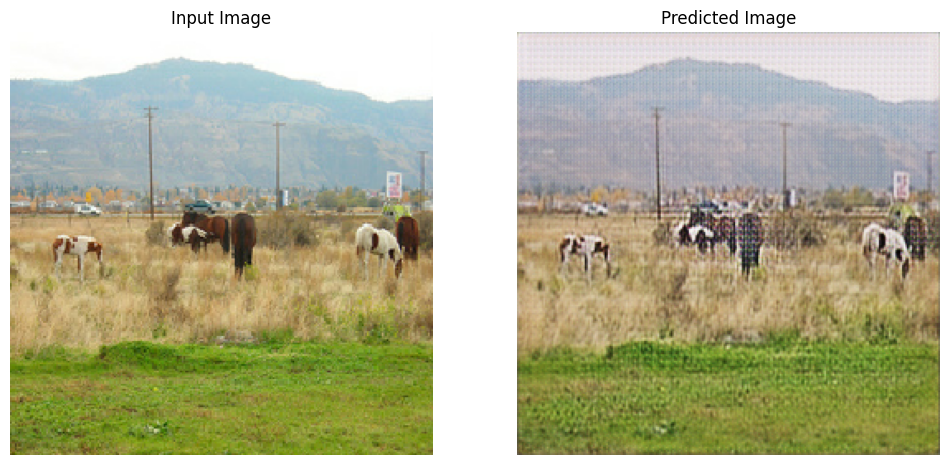

Time taken for epoch 1 is 549.0060842037201 sec

........................................................

In [ ]:
with tf.device("/GPU:0"):
  for epoch in range(EPOCHS):
    start = time.time()

    n = 0
    for image_x, image_y in tf.data.Dataset.zip((train_horses, train_zebras)):
      train_step(image_x, image_y)
      if n % 10 == 0:
        print ('.', end='')
      n += 1

    clear_output(wait=True)
    # Using a consistent image (sample_horse) so that the progress of the model
    # is clearly visible.
    generate_images(Generator_G, sample_horse)

    if (epoch + 1) % 5 == 0:
      ckpt_save_path = ckpt_manager.save()
      print ('Saving checkpoint for epoch {} at {}'.format(epoch+1,
                                                          ckpt_save_path))

    print ('Time taken for epoch {} is {} sec\n'.format(epoch + 1,
                                                        time.time()-start))

In [ ]:
for inp in test_horses.take(5):
  generate_images(Generator_G, inp)